# Actividad 3. Simulación del problema bancario
**Asignatura:** Simulación  - Ingenieria desarrollo de software y bases de datos

**Estudiante:** Daniela María Sánchez Sánchez  
**Herramientas:** Python y Google Colab


**Fecha:**  20-11-2026


## ¿Qué quiero estudiar?
En este trabajo comparo diferentes formas de organizar las cajas de un banco. El ejercicio usa las tablas del laboratorio del profesor: tres cajas, ocho horas al día, 70 % de retiros y 30 % de pagos. La idea es conocer los tiempos de espera, los usuarios atendidos y si conviene asignar cajas exclusivas o mantenerlas mixtas.

**Importante:** los resultados son de una simulación académica, no de un banco real.

## 1. Datos que tomé del laboratorio

Las ocho clases de clientes son combinaciones de operación (**Retiro/Pago**) y tipo (**Rápido/Normal/Lento/Muy lento**).

| Operación | Tipo | Servicio medio (min) | Llegada media de referencia (min) | Probabilidad dentro de operación |
|---|---|---:|---:|---:|
| Retiro | Rápido | 1 | 1 | 0,23 |
| Retiro | Normal | 2 | 2 | 0,40 |
| Retiro | Lento | 3 | 3 | 0,17 |
| Retiro | Muy lento | 4 | 3 | 0,20 |
| Pago | Rápido | 3 | 1 | 0,10 |
| Pago | Normal | 3 | 2 | 0,20 |
| Pago | Lento | 5 | 3 | 0,30 |
| Pago | Muy lento | 7 | 4 | 0,40 |

**Decisión de modelado:** para mantener llegadas con tiempos entre eventos exponenciales (Poisson), calculé **una media global ponderada** con los valores de llegada del laboratorio. Luego asigné 70 % de retiros y 30 % de pagos; los tiempos de servicio se generan de forma exponencial con la media de la categoría correspondiente. Así se conserva la proporción de usuarios y se utilizan las tablas como parámetros. Esto **no reproduce literalmente una tasa de llegada distinta para cada subtipo**, ni es un M/M/1 exacto con distribución de servicio única, sino una aproximación de colas independientes con servicios por categoría. La limitación se reporta en las conclusiones.

## 2. Código base y modificaciones
Tomé como referencia la estructura `BankSimulation` de la guía. Conservé las ideas de generar tiempos exponenciales, determinar la operación y el tipo de usuario y repetir días simulados.

Las partes que amplié fueron: **una cola FIFO independiente por cajero**, la asignación solo a cajas que acepten la operación, seis configuraciones para comparar, resultados por réplica y por cajero, medición de usuarios que alcanzan a terminar antes del cierre y cálculo de intervalos de confianza.

Para comparar los modelos de manera justa, **cada réplica usa exactamente las mismas llegadas y los mismos tiempos de servicio en todas las configuraciones**. El banco recibe usuarios durante 480 minutos; quienes llegan antes del cierre terminan su turno aunque el servicio acabe después.

In [1]:
"""Tercera actividad de Ingeniería de Simulación: problema bancario.
Adaptación ampliada del ejemplo BankSimulation compartido en el laboratorio.
Los datos son supuestos del ejercicio, no observaciones de un banco real.
"""
from dataclasses import dataclass
import numpy as np
import pandas as pd
from scipy.stats import t as student_t

TIPOS = ['Rápido', 'Normal', 'Lento', 'Muy lento']
CONFIGURACIONES = {
    '3 mixtas': ['Mixto', 'Mixto', 'Mixto'],
    '1 retiro + 2 pagos': ['Retiro', 'Pago', 'Pago'],
    '2 retiros + 1 pago': ['Retiro', 'Retiro', 'Pago'],
    '4 mixtas': ['Mixto', 'Mixto', 'Mixto', 'Mixto'],
    '2 retiros + 2 pagos': ['Retiro', 'Retiro', 'Pago', 'Pago'],
    '3 retiros + 1 pago': ['Retiro', 'Retiro', 'Retiro', 'Pago'],
}

class BankSimulation:
    def __init__(self, horas_operacion=8, semilla_base=2026):
        self.minutos = int(horas_operacion * 60)
        self.semilla_base = int(semilla_base)
        self.prob_retiro = 0.70
        self.prob_pago = 0.30
        self.prob_usuario_retiro = np.array([0.23, 0.40, 0.17, 0.20])
        self.prob_usuario_pago = np.array([0.10, 0.20, 0.30, 0.40])
        self.servicio_retiro = np.array([1., 2., 3., 4.])
        self.servicio_pago = np.array([3., 3., 5., 7.])
        self.llegada_retiro = np.array([1., 2., 3., 3.])
        self.llegada_pago = np.array([1., 2., 3., 4.])
        # Supuesto explícito: para mantener llegadas Poisson, usamos una sola
        # distribución exponencial global, con media ponderada de la tabla 1.
        # No equivale a exigir tiempos entre llegadas por subtipo por separado.
        self.media_entre_llegadas = (
            self.prob_retiro * np.dot(self.prob_usuario_retiro, self.llegada_retiro)
            + self.prob_pago * np.dot(self.prob_usuario_pago, self.llegada_pago)
        )
        assert np.isclose(self.prob_retiro + self.prob_pago, 1)
        assert np.isclose(self.prob_usuario_retiro.sum(), 1)
        assert np.isclose(self.prob_usuario_pago.sum(), 1)

    def generar_tiempo_exponencial(self, media, rng):
        return float(rng.exponential(media))

    def generar_tipo_accion(self, rng):
        return 'Retiro' if rng.random() < self.prob_retiro else 'Pago'

    def generar_tipo_usuario(self, accion, rng):
        p = self.prob_usuario_retiro if accion == 'Retiro' else self.prob_usuario_pago
        return int(rng.choice(4, p=p))

    def generar_usuarios(self, replica):
        """La misma lista de personas se utiliza en todos los escenarios de una réplica."""
        rng = np.random.default_rng(self.semilla_base + int(replica))
        tiempo = 0.0
        filas = []
        while True:
            tiempo += self.generar_tiempo_exponencial(self.media_entre_llegadas, rng)
            if tiempo >= self.minutos:
                break
            accion = self.generar_tipo_accion(rng)
            tipo = self.generar_tipo_usuario(accion, rng)
            media_servicio = (self.servicio_retiro if accion == 'Retiro' else self.servicio_pago)[tipo]
            filas.append({
                'cliente': len(filas) + 1, 'replica': int(replica),
                'minuto_llegada': tiempo, 'operacion': accion,
                'tipo_usuario': TIPOS[tipo], 'minutos_servicio': self.generar_tiempo_exponencial(media_servicio, rng)
            })
        return pd.DataFrame(filas)

    def simular_dia(self, usuarios, configuracion, replica):
        """Una fila FIFO independiente por cajero y asignación a la menor fila elegible."""
        funciones = CONFIGURACIONES[configuracion]
        n = len(funciones)
        finales = [[] for _ in range(n)]
        disponible = np.zeros(n, dtype=float)
        resultados = []
        for fila in usuarios.itertuples(index=False):
            t_llegada = float(fila.minuto_llegada)
            elegibles = [j for j, tipo in enumerate(funciones) if tipo in ('Mixto', fila.operacion)]
            # Los clientes eligen la fila elegible con menos personas presentes.
            # Si hay empate, rotamos la prioridad para distribuir las entradas.
            j = min(elegibles, key=lambda k: (
                sum(fin > t_llegada for fin in finales[k]), (k - int(fila.cliente)) % n
            ))
            inicio = max(t_llegada, float(disponible[j]))
            fin = inicio + float(fila.minutos_servicio)
            espera = inicio - t_llegada
            disponible[j] = fin
            finales[j].append(fin)
            resultados.append({
                'replica': int(replica), 'configuracion': configuracion,
                'cajero': j + 1, 'tipo_cajero': funciones[j],
                'cliente': int(fila.cliente), 'operacion': fila.operacion,
                'tipo_usuario': fila.tipo_usuario, 'llegada_min': t_llegada,
                'inicio_min': inicio, 'fin_min': fin,
                'servicio_min': float(fila.minutos_servicio),
                'espera_min': espera, 'sistema_min': espera + float(fila.minutos_servicio),
                'termino_hasta_cierre': bool(fin <= self.minutos),
                'ocupacion_durante_turno_min': max(0., min(fin, self.minutos) - max(inicio, 0.))
            })
        return pd.DataFrame(resultados)

    def ejecutar_replicas(self, num_replicas=30):
        registros = []
        metricas = []
        por_cajero = []
        for replica in range(1, num_replicas + 1):
            usuarios = self.generar_usuarios(replica)
            for config in CONFIGURACIONES:
                df = self.simular_dia(usuarios, config, replica)
                registros.append(df)
                atendidos = int(df['termino_hasta_cierre'].sum())
                metricas.append({
                    'replica': replica, 'configuracion': config,
                    'cajeros': len(CONFIGURACIONES[config]),
                    'llegadas': len(df), 'retiros_llegados': int((df.operacion == 'Retiro').sum()),
                    'pagos_llegados': int((df.operacion == 'Pago').sum()),
                    'atendidos_hasta_cierre': atendidos,
                    'pendientes_al_cierre': int(len(df) - atendidos),
                    'espera_media_min': float(df.espera_min.mean()),
                    'espera_p90_min': float(df.espera_min.quantile(0.90)),
                    'servicio_medio_min': float(df.servicio_min.mean()),
                    'tiempo_sistema_medio_min': float(df.sistema_min.mean()),
                    'espera_retiros_min': float(df.loc[df.operacion == 'Retiro','espera_min'].mean()),
                    'espera_pagos_min': float(df.loc[df.operacion == 'Pago','espera_min'].mean()),
                    'ultima_salida_min': float(df.fin_min.max()),
                    'salida_despues_del_cierre_min': max(0., float(df.fin_min.max()) - self.minutos),
                    'utilizacion_media_pct': float(100 * df['ocupacion_durante_turno_min'].sum() / (self.minutos*len(CONFIGURACIONES[config]))),
                })
                for j, etiqueta in enumerate(CONFIGURACIONES[config], 1):
                    z = df.loc[df.cajero == j]
                    por_cajero.append({
                        'replica': replica, 'configuracion': config,
                        'cajero': j, 'tipo_cajero': etiqueta,
                        'clientes': int(len(z)), 'atendidos_hasta_cierre': int(z.termino_hasta_cierre.sum()),
                        'servicio_medio_min': float(z.servicio_min.mean()) if len(z) else np.nan,
                        'espera_media_min': float(z.espera_min.mean()) if len(z) else np.nan,
                        'utilizacion_pct': 100 * float(z.ocupacion_durante_turno_min.sum()) / self.minutos,
                    })
        return pd.concat(registros, ignore_index=True), pd.DataFrame(metricas), pd.DataFrame(por_cajero)

def intervalo_95(serie):
    x = pd.Series(serie).dropna()
    n = len(x)
    if n < 2:
        return (np.nan, np.nan)
    m = float(x.mean())
    margen = float(student_t.ppf(0.975, n-1) * x.std(ddof=1) / np.sqrt(n))
    return m - margen, m + margen

def resumir_replicas(tabla):
    filas = []
    for config, x in tabla.groupby('configuracion', sort=False):
        li, ls = intervalo_95(x.espera_media_min)
        filas.append({
            'configuracion': config, 'n_replicas': int(len(x)),
            'llegadas_promedio': x.llegadas.mean(),
            'atendidos_hasta_cierre_promedio': x.atendidos_hasta_cierre.mean(),
            'pendientes_al_cierre_promedio': x.pendientes_al_cierre.mean(),
            'espera_media_min': x.espera_media_min.mean(),
            'desviacion_espera_min': x.espera_media_min.std(ddof=1),
            'min_espera_min': x.espera_media_min.min(),
            'max_espera_min': x.espera_media_min.max(),
            'IC95_inferior_min': li, 'IC95_superior_min': ls,
            'espera_p90_min': x.espera_p90_min.mean(),
            'espera_retiros_min': x.espera_retiros_min.mean(),
            'espera_pagos_min': x.espera_pagos_min.mean(),
            'servicio_medio_min': x.servicio_medio_min.mean(),
            'utilizacion_media_pct': x.utilizacion_media_pct.mean(),
        })
    return pd.DataFrame(filas)



## 3. Primera comprobación y ejecución
Uso **30 réplicas de 8 horas por configuración** (más de las 10 exigidas) y una semilla base igual a 2026. Cada réplica representa un día independiente. Cada cajero tiene su propia fila y atiende una persona a la vez.

In [2]:
import platform
import matplotlib.pyplot as plt
from IPython.display import display

NUM_REPLICAS = 30
simulador = BankSimulation(horas_operacion=8, semilla_base=2026)
print('Media global entre llegadas (min):', round(simulador.media_entre_llegadas, 3))
print('Python:', platform.python_version(), '| NumPy:', np.__version__, '| Pandas:', pd.__version__)
print('Semilla base:', simulador.semilla_base)

# Realizo las réplicas con las mismas personas para todas las opciones
clientes, replicas, por_cajero_replica = simulador.ejecutar_replicas(NUM_REPLICAS)
resumen = resumir_replicas(replicas)
display(resumen[['configuracion', 'espera_media_min', 'desviacion_espera_min',
                  'IC95_inferior_min','IC95_superior_min','pendientes_al_cierre_promedio']].round(2))

Media global entre llegadas (min): 2.398
Python: 3.13.18 | NumPy: 2.4.6 | Pandas: 2.2.3
Semilla base: 2026


,configuracion,espera_media_min,desviacion_espera_min,IC95_inferior_min,IC95_superior_min,pendientes_al_cierre_promedio
0,3 mixtas,0.66,0.34,0.53,0.78,1.67
1,1 retiro + 2 pagos,4.46,2.49,3.53,5.39,3.40
2,2 retiros + 1 pago,2.78,2.08,2.01,3.56,2.53
3,4 mixtas,0.17,0.12,0.12,0.21,1.43
4,2 retiros + 2 pagos,0.59,0.25,0.50,0.69,1.63
5,3 retiros + 1 pago,2.50,2.06,1.73,3.27,2.40


## 4. Punto 1: ¿qué cajero tiene menor o mayor tiempo de atención?
Para este punto utilizo el **tiempo de servicio** (sin sumarle la espera). Como todos los cajeros tienen la misma velocidad para una operación equivalente, las pequeñas diferencias pueden aparecer porque reciben clientes con distintas categorías. Uso las **tres cajas mixtas** para comparar los tres cajeros.

,configuracion,cajero,servicio_medio_min,espera_media_min,personas
10,3 mixtas,1,3.19,0.66,1947
11,3 mixtas,2,3.24,0.69,1970
12,3 mixtas,3,3.05,0.67,2025


Menor tiempo de atención: cajero 3
Mayor tiempo de atención: cajero 2


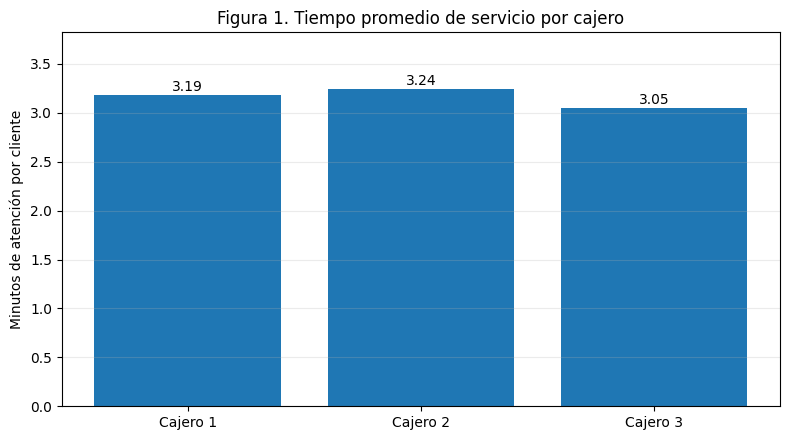

In [3]:
tabla_cajeros = (clientes.groupby(['configuracion','cajero'], as_index=False)
                 .agg(servicio_medio_min=('servicio_min','mean'),
                      espera_media_min=('espera_min','mean'),
                      personas=('cliente','size')))
mixtos = tabla_cajeros.query('configuracion == "3 mixtas"').sort_values('cajero')
display(mixtos.round(2))
print('Menor tiempo de atención: cajero',int(mixtos.loc[mixtos.servicio_medio_min.idxmin(),'cajero']))
print('Mayor tiempo de atención: cajero',int(mixtos.loc[mixtos.servicio_medio_min.idxmax(),'cajero']))

fig, ax = plt.subplots(figsize=(8,4.5))
ax.bar(['Cajero '+str(x) for x in mixtos.cajero], mixtos.servicio_medio_min)
ax.set_title('Figura 1. Tiempo promedio de servicio por cajero')
ax.set_ylabel('Minutos de atención por cliente'); ax.grid(axis='y',alpha=.25)
for i,v in enumerate(mixtos.servicio_medio_min): ax.text(i,v+.04,f'{v:.2f}',ha='center')
ax.set_ylim(0,mixtos.servicio_medio_min.max()*1.18)
fig.tight_layout();fig.savefig('Figura_01_Servicio_Cajeros.png',dpi=300,bbox_inches='tight');plt.show()

**Análisis de la figura 1:** los tres cajeros tienen tiempos cercanos porque se les asigna la misma distribución de servicios; la diferencia observada no demuestra que una persona atienda mejor que otra. El gráfico permite identificar el menor y mayor promedio de esta simulación.

## 5. Punto 2: promedio de usuarios por tipo de cliente
Aquí cuento personas que **llegaron** durante las ocho horas. El número de llegadas es el mismo en todos los modelos porque se usa la misma muestra para compararlos.

,configuracion,operacion,tipo_usuario,llegaron,finalizaron
24,3 mixtas,Pago,Lento,17.13,17.07
25,3 mixtas,Pago,Muy lento,24.03,23.53
26,3 mixtas,Pago,Normal,11.27,11.17
27,3 mixtas,Pago,Rápido,6.33,6.33
28,3 mixtas,Retiro,Lento,24.60,24.47
29,3 mixtas,Retiro,Muy lento,28.57,28.30
30,3 mixtas,Retiro,Normal,54.10,53.63
31,3 mixtas,Retiro,Rápido,32.03,31.90


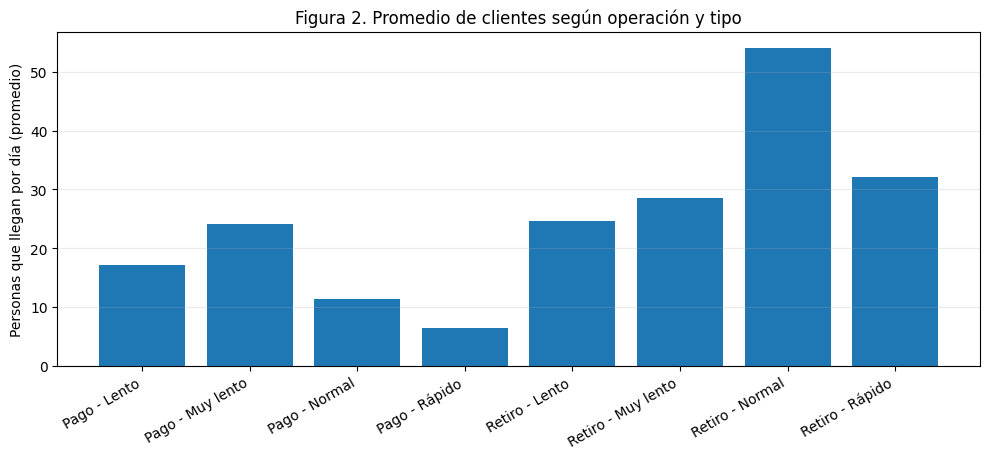

In [4]:
tipos = ['Rápido', 'Normal', 'Lento', 'Muy lento']
tipo = (clientes.groupby(['configuracion','replica','operacion','tipo_usuario'])
        .agg(llegaron=('cliente','size'), finalizaron=('termino_hasta_cierre','sum')))
ix = pd.MultiIndex.from_product([list(CONFIGURACIONES),range(1,NUM_REPLICAS+1),
                                ['Retiro','Pago'],tipos],
                                names=['configuracion','replica','operacion','tipo_usuario'])
tipo = tipo.reindex(ix,fill_value=0).reset_index()
prom_tipo = tipo.groupby(['configuracion','operacion','tipo_usuario'],as_index=False)[['llegaron','finalizaron']].mean()
res_tip = prom_tipo.query('configuracion == "3 mixtas"')
display(res_tip.round(2))
fig,ax = plt.subplots(figsize=(10,4.7))
etiq = [f'{a} - {t}' for a,t in zip(res_tip.operacion,res_tip.tipo_usuario)]
ax.bar(range(len(res_tip)),res_tip.llegaron)
ax.set_xticks(range(len(res_tip)),etiq,rotation=30,ha='right')
ax.set_ylabel('Personas que llegan por día (promedio)')
ax.set_title('Figura 2. Promedio de clientes según operación y tipo')
ax.grid(axis='y',alpha=.25);fig.tight_layout()
fig.savefig('Figura_02_Tipos_Usuarios.png',dpi=300,bbox_inches='tight');plt.show()

**Análisis de la figura 2:** el volumen de personas por clase depende de la probabilidad de retiros/pagos y de la probabilidad de ser rápido, normal, lento o muy lento dentro de esa operación. No todos los clientes requieren el mismo tiempo de servicio.

## 6. Punto 3: usuarios por réplica y modelo
En esta tabla muestro cuántos clientes terminaron su trámite **antes de que cerrara el banco**. Por eso un modelo puede tener menos clientes atendidos que otro aunque les hayan llegado exactamente las mismas personas.

configuracion,1 retiro + 2 pagos,2 retiros + 1 pago,2 retiros + 2 pagos,3 mixtas,3 retiros + 1 pago,4 mixtas
replica,,,,,,
1,205,199,206,206,199,206
2,181,181,182,182,181,182
3,203,203,203,203,203,203
4,187,187,188,188,188,189
5,193,194,194,194,194,194
6,198,201,201,201,201,202
7,212,213,214,214,214,214
8,172,172,172,172,172,172
9,201,201,201,201,201,201


configuracion           1 retiro + 2 pagos  2 retiros + 1 pago  \
operacion tipo_usuario                                           
Pago      Lento                      17.03               16.80   
          Muy lento                  23.53               23.13   
          Normal                     11.20               11.03   
          Rápido                      6.30                6.23   
Retiro    Lento                      24.17               24.43   
          Muy lento                  28.03               28.33   
          Normal                     52.83               53.67   
          Rápido                     31.57               31.90   

configuracion           2 retiros + 2 pagos  3 mixtas  3 retiros + 1 pago  \
operacion tipo_usuario                                                      
Pago      Lento                       17.03     17.07               16.80   
          Muy lento                   23.57     23.53               23.13   
          Normal                      11.20     11.17               11.03   
          Rápido                       6.33      6.33                6.23   
Retiro    Lento                       24.40     24.47               24.47   
          Muy lento                   28.33     28.30               28.37   
          Normal                      53.70     53.63               53.73   
          Rápido                      31.87     31.90               31.90   

configuracion           4 mixtas  
operacion tipo_usuario            
Pago      Lento            17.07  
          Muy lento        23.60  
          Normal           11.20  
          Rápido            6.33  
Retiro    Lento            24.47  
          Muy lento        28.33  
          Normal           53.73  
          Rápido           31.90

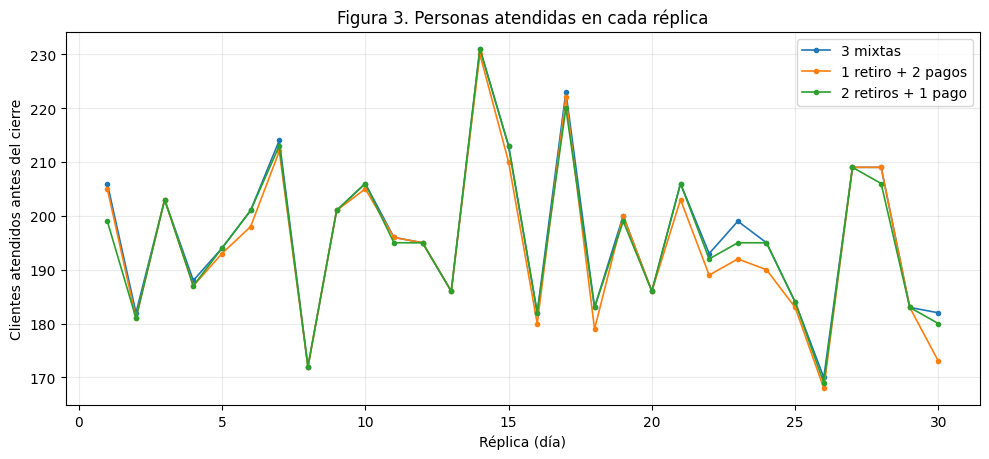

In [5]:
tabla_replica = replicas.pivot(index='replica',columns='configuracion',values='atendidos_hasta_cierre')
display(tabla_replica)
resumen_tipo = tipo.groupby(['configuracion','operacion','tipo_usuario'],as_index=False)['finalizaron'].mean()
display(resumen_tipo.pivot_table(index=['operacion','tipo_usuario'],
                                 columns='configuracion',values='finalizaron').round(2))
fig,ax = plt.subplots(figsize=(10,4.7))
for conf in ['3 mixtas','1 retiro + 2 pagos','2 retiros + 1 pago']:
    ax.plot(tabla_replica.index,tabla_replica[conf],marker='.',label=conf,linewidth=1.2)
ax.set_xlabel('Réplica (día)');ax.set_ylabel('Clientes atendidos antes del cierre')
ax.set_title('Figura 3. Personas atendidas en cada réplica')
ax.legend();ax.grid(alpha=.25);fig.tight_layout()
fig.savefig('Figura_03_Replicas.png',dpi=300,bbox_inches='tight');plt.show()

**Análisis de la figura 3:** los resultados cambian entre días porque las llegadas y los servicios son aleatorios. El modelo que atienda menos clientes de un tipo **no es necesariamente mejor**: puede significar que quedaron más personas pendientes al cierre. El archivo CSV incluye la información de las 30 réplicas y los ocho subtipos.

## 7. Punto 4: espera promedio y necesidad de una cuarta caja
Comparo la espera en los distintos modelos. Las barras de error corresponden al **intervalo de confianza del 95 %** para la media de la espera diaria, calculado entre 30 réplicas. El criterio de cinco minutos de espera promedio es un objetivo de servicio **propuesto para este ejercicio**, no un dato del banco.

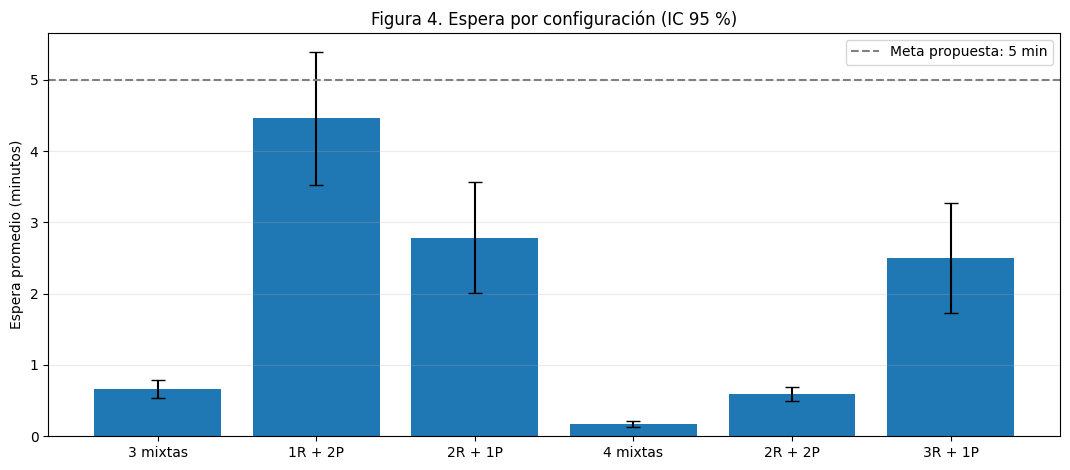

In [6]:
orden = list(CONFIGURACIONES)
r = resumen.set_index('configuracion').loc[orden]
fig,ax=plt.subplots(figsize=(10.8,4.8))
vals=r.espera_media_min.to_numpy()
ax.bar(range(len(orden)),vals,
       yerr=[vals-r.IC95_inferior_min.to_numpy(),r.IC95_superior_min.to_numpy()-vals],capsize=5)
ax.set_xticks(range(len(orden)),['3 mixtas','1R + 2P','2R + 1P','4 mixtas','2R + 2P','3R + 1P'])
ax.axhline(5,linestyle='--',color='gray',label='Meta propuesta: 5 min')
ax.set_ylabel('Espera promedio (minutos)');ax.set_title('Figura 4. Espera por configuración (IC 95 %)')
ax.legend();ax.grid(axis='y',alpha=.25)
fig.tight_layout();fig.savefig('Figura_04_Espera_Intervalos.png',dpi=300,bbox_inches='tight');plt.show()

**Análisis de la figura 4:** es el indicador principal para elegir una configuración. La comparación con cuatro cajas sirve para comprobar cuánto se reduce la espera y decidir si el beneficio justifica el costo adicional. No se puede afirmar que abrir otra caja sea necesario sin establecer un objetivo y valorar el costo.

De acuerdo con los resultados, considero que no es necesario agregar una cuarta caja por el momento. Con tres cajas mixtas, los usuarios esperan aproximadamente 0,66 minutos, un tiempo inferior a la meta de cinco minutos propuesta para este ejercicio. Aunque la cuarta caja reduce la espera a 0,17 minutos, primero sería necesario revisar los costos para determinar si vale la pena contratar otro cajero.

## 8. Punto 5: distribución y estrategia de servicio
No elijo únicamente por el 70 % de retiros: también comparo cuánto se demoran los pagos, que tienen medias de servicio mayores. Aquí analizo la espera de cada operación para observar si una asignación perjudica a alguno de los grupos.

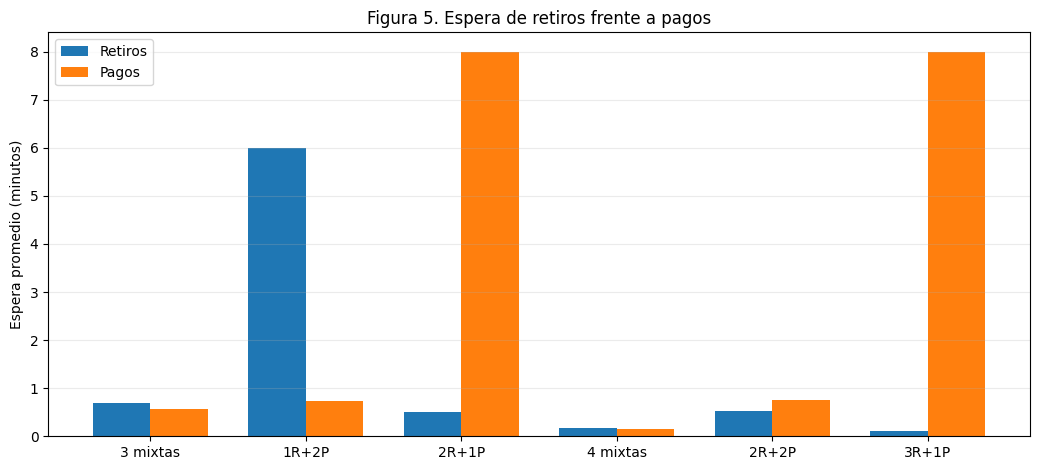

Mejor alternativa de 3 cajas: 3 mixtas
Mejor distribución si obligatoriamente son exclusivas: 2 retiros + 1 pago
Espera de 3 mixtas: 0.66 min
Espera de 4 mixtas: 0.17 min


In [7]:
fig,ax=plt.subplots(figsize=(10.5,4.8))
x=np.arange(len(orden));w=.37
ax.bar(x-w/2,r.espera_retiros_min,width=w,label='Retiros')
ax.bar(x+w/2,r.espera_pagos_min,width=w,label='Pagos')
ax.set_xticks(x,['3 mixtas','1R+2P','2R+1P','4 mixtas','2R+2P','3R+1P'])
ax.set_ylabel('Espera promedio (minutos)');ax.set_title('Figura 5. Espera de retiros frente a pagos')
ax.legend();ax.grid(axis='y',alpha=.25);fig.tight_layout()
fig.savefig('Figura_05_Espera_Operacion.png',dpi=300,bbox_inches='tight');plt.show()

solo_tres=resumen[resumen.configuracion.isin(['3 mixtas','1 retiro + 2 pagos','2 retiros + 1 pago'])]
solo_exclusivas=resumen[resumen.configuracion.isin(['1 retiro + 2 pagos','2 retiros + 1 pago'])]
mejor_tres=solo_tres.sort_values('espera_media_min').iloc[0]
mejor_exclusivas=solo_exclusivas.sort_values('espera_media_min').iloc[0]
print('Mejor alternativa de 3 cajas:',mejor_tres.configuracion)
print('Mejor distribución si obligatoriamente son exclusivas:',mejor_exclusivas.configuracion)
print('Espera de 3 mixtas:',round(float(r.loc['3 mixtas','espera_media_min']),2),'min')
print('Espera de 4 mixtas:',round(float(r.loc['4 mixtas','espera_media_min']),2),'min')

Al comparar las cajas exclusivas, observé que la distribución de dos cajeros para retiros y uno para pagos presenta mejores resultados generales que la opción contraria. Sin embargo, los usuarios que realizan pagos tienen una espera aproximada de ocho minutos. Por esta razón, considero que la mejor estrategia es mantener las tres cajas mixtas, porque así se distribuye mejor la atención entre ambos tipos de operaciones.

**Estrategia propuesta a partir de estas simulaciones:**

- Mientras el banco pueda operar con cajas mixtas, conviene mantener **3 cajas mixtas** y distribuir a cada persona en la fila elegible menos ocupada.
- Si la decisión institucional exige **cajas exclusivas**, el modelo con **2 retiros y 1 pago** obtiene menor espera global que la alternativa de 1 retiro y 2 pagos. No significa que todos los clientes esperen poco: hay que vigilar especialmente la fila de pagos.
- Para manejar picos, se puede organizar una fila visible por caja, informar el tiempo estimado y autorizar un **apoyo temporal entre operaciones** cuando una fila crezca; esto último debe evaluarse como un nuevo escenario si se aplica, porque ya no sería totalmente exclusivo.
- Con **4 cajas mixtas** la espera baja más, pero los datos por sí solos no demuestran que sea necesario pagar otra caja. Conviene decidirlo usando una meta de servicio y los costos de personal.

Estas son conclusiones para el **modelo simulado**, no decisiones definitivas para un banco real.

## 9. Pruebas de reproducibilidad y exportación
Valido que no haya tiempos negativos, que las 30 réplicas se hayan ejecutado para las seis configuraciones y que cada escenario use igual número de clientes en la misma réplica. También guardo los CSV para poder revisar los cálculos en Excel.

In [8]:
assert (clientes.espera_min >= 0).all()
assert (clientes.servicio_min > 0).all()
assert (clientes.fin_min >= clientes.inicio_min).all()
assert len(replicas) == NUM_REPLICAS * len(CONFIGURACIONES)
assert (replicas.groupby('replica').llegadas.nunique() == 1).all()
assert simulador.generar_usuarios(1).equals(simulador.generar_usuarios(1))

clientes.to_csv('01_Detalle_Usuarios.csv',index=False,encoding='utf-8-sig')
replicas.to_csv('02_Resumen_Replicas.csv',index=False,encoding='utf-8-sig')
tipo.to_csv('03_Usuarios_Por_Tipo.csv',index=False,encoding='utf-8-sig')
por_cajero_replica.to_csv('04_Por_Cajero.csv',index=False,encoding='utf-8-sig')
resumen.to_csv('05_Comparacion_Escenarios.csv',index=False,encoding='utf-8-sig')
print('Comprobaciones correctas. CSV generados. El cuaderno está listo para revisión.')

Comprobaciones correctas. CSV generados. El cuaderno está listo para revisión.


## 10. Conclusión del ejercicio
Al trabajar con el modelo entendí que **tiempo de atención** y **tiempo de espera** no son lo mismo. También comprobé que la mejor manera de distribuir cajeros depende de cuántos usuarios llegan, cuánto tarda cada trámite y cómo se organizan las filas.

En los datos de este ejercicio las **3 cajas mixtas** reducen más la espera que las dos distribuciones exclusivas de tres cajas. Si debo escoger entre asignar **1 retiro + 2 pagos** o **2 retiros + 1 pago**, recomiendo la segunda, con supervisión del tiempo de espera en pagos. El análisis de una cuarta caja se presenta como comparación de mejora, no como una obligación automática.

### Limitaciones que debo mencionar en el informe
1. Los datos son los proporcionados en el laboratorio y se usaron como parámetros para generar clientes simulados.
2. La media global de llegadas es una decisión metodológica para conservar un proceso Poisson. No respeta literalmente ocho tasas de llegada diferentes a la vez.
3. Los tiempos de servicio son exponenciales **condicionados al tipo de usuario**. La mezcla entre categorías no es exactamente un M/M/1 homogéneo; es una aproximación de colas con un servidor y servicio heterogéneo.
4. No se conocen los costos de contratar otro cajero ni una meta oficial de espera; por eso la estrategia es una recomendación académica, no una decisión empresarial definitiva.

**Material base:** Laboratorio «Problema Bancario – Simulación de sistemas de colas», suministrado en la asignatura.